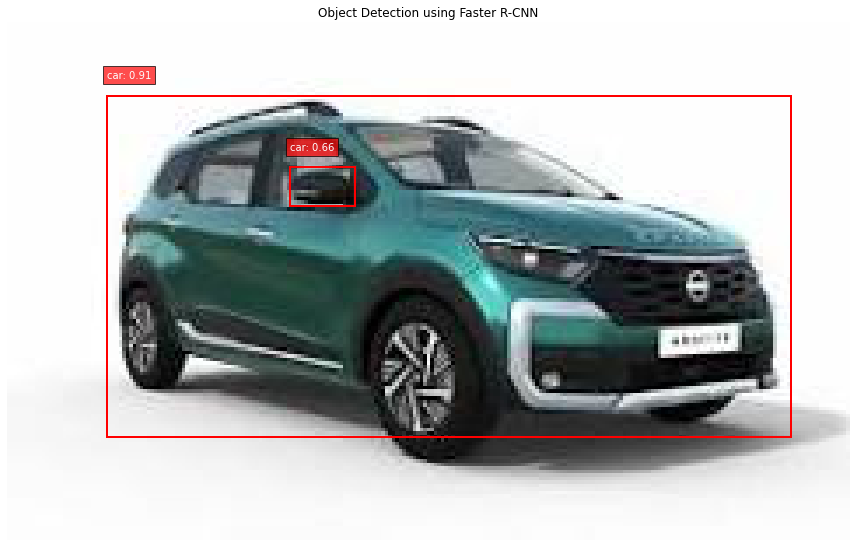

Code execution complete.
Objects detected: 2


In [13]:
# Object Detection using Faster R-CNN

import torch
import torchvision
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from PIL import Image
from tkinter import Tk, filedialog

# 1. Select an image
root = Tk()
root.withdraw()

image_path = filedialog.askopenfilename(
    title="Select an image",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png *.bmp"),
        ("All files", "*.*")
    ]
)

root.destroy()

if not image_path:
    raise ValueError("No image selected!")

# 2. Load the image
image = Image.open(image_path).convert("RGB")

# 3. Load the pretrained Faster R-CNN model
weights = torchvision.models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT

model = torchvision.models.detection.fasterrcnn_resnet50_fpn(
    weights=weights
)

model.eval()

# 4. Preprocess the image
transform = weights.transforms()
image_tensor = transform(image)

# 5. Detect objects
with torch.no_grad():
    predictions = model([image_tensor])[0]

# 6. Get class names
categories = weights.meta["categories"]
threshold = 0.5

# 7. Display detection results
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)

detected = 0

for box, label, score in zip(
    predictions["boxes"],
    predictions["labels"],
    predictions["scores"]
):
    if score.item() >= threshold:
        x1, y1, x2, y2 = box.tolist()
        label_name = categories[label.item()]

        # Draw bounding box
        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

        # Display class name and confidence
        ax.text(
            x1,
            max(0, y1 - 5),
            f"{label_name}: {score.item():.2f}",
            color="white",
            bbox=dict(facecolor="red", alpha=0.7)
        )

        detected += 1

ax.axis("off")
plt.title("Object Detection using Faster R-CNN")
plt.tight_layout()
plt.show()

print("Code execution complete.")
print("Objects detected:", detected)


In [7]:
%pip install "tensorflow-hub<0.16" tensorflow-datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install --upgrade setuptools

Requirement already up-to-date: setuptools in /home/ubuntu/anaconda3/lib/python3.8/site-packages (75.3.4)
Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install torchvision

Note: you may need to restart the kernel to use updated packages.
